**Forward:**

$$
\frac{\partial u}{\partial t} = D \frac{\partial^2 u}{\partial x^2}, \quad x \in [-1, 1], \quad t \in [0, 1]
$$

Boundary conditions (Dirichlet): $$u(-1, t) = u(1, t) = 0$$

Initial conditions: $$u(x, 0) = \sin(\pi x)$$

**Backwardа:**

It is assumed that the true value of \(D\) is unknown. We generate synthetic noisy “experimental” data based on the analytical solution with \(D_{true} = 1.0\). The goal of PINN is to find the value of \(D_{pred}\) by minimizing the residual of the equation and the error relative to the observations.

In [1]:
import numpy as np
import torch
import deepxde as dde
import pandas as pd

from matplotlib import pyplot as plt

rng = np.random.default_rng(42)
dde.config.set_random_seed(42)

Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.


In [2]:
log_D = dde.Variable(-1.0)

def diffusion_coef():
    return torch.exp(log_D)

D_true = 0.30
L, T = 1.0, 1.0

### Define the initial conditions of our problem and create the space in which the solution will take place (the combination of geometric and temporal spaces).

In [3]:
geometric_interval = dde.geometry.Interval(-L, L)
time_interval = dde.geometry.TimeDomain(0, T)

full_domain = dde.geometry.GeometryXTime(geometric_interval, time_interval)

### PDE function and the residual of the resulting equation.

In [4]:
def pde (x, y):
    dy_t = dde.grad.jacobian(y, x, i=0, j=1)
    dy_xx = dde.grad.hessian(y, x, i=0, j=0)

    res = dy_t - diffusion_coef() * dy_xx

    return res

def exact_value(x, D=D_true):
    return np.sin(np.pi * x[:, 0:1]) * np.exp(-np.pi**2 * D * x[:, 1:2])


### Specifying the boundary and initial conditions of the equation.

In [5]:
boundary_conditions = dde.icbc.DirichletBC(
    full_domain,
    lambda x: np.zeros((len(x), 1)),
    lambda _, on_b: on_b
    )

initial_conditions = dde.icbc.IC(
    full_domain,
    lambda x: np.sin(np.pi * x[:, 0:1]),
    lambda _, on_i: on_i
)


### Adding “experimental data” and assembling the Data object (creating PINN training Config)

In [6]:
N = 120
sigma = 0.1

n_temp = int(0.7 * N)
t_obs = np.concatenate([rng.uniform(0.0, 0.35, n_temp),
                        rng.uniform(0.35, T, N - n_temp)]).reshape(-1, 1)

x_grade = np.linspace(-L, L, 20001)
cdf = np.cumsum(np.abs(np.sin(np.pi * x_grade))) 

cdf /= cdf[-1]
x_observed = np.interp(rng.uniform(0, 1, N), cdf, x_grade).reshape(-1, 1)

X_obs = np.hstack([x_observed, t_obs])
u_obs = exact_value(X_obs) + sigma * rng.standard_normal((N, 1))

observe = dde.icbc.PointSetBC(X_obs, u_obs, component=0) 

data = dde.data.TimePDE(
    full_domain, pde,
    [boundary_conditions, initial_conditions, observe],
    num_domain=4000, num_boundary=200, num_initial=400, num_test=2000,
)

### Model train

In [ ]:
net = dde.nn.FNN([2] + [128] * 4 + [1], "tanh", "Glorot uniform")

model = dde.Model(data, net)
weights = [1.0, 10.0, 10.0, 100.0] 

model.compile("adam", lr=0.001, loss_weights=weights, external_trainable_variables=[log_D])

var_callback = dde.callbacks.VariableValue([log_D], period=200, filename="variables.dat", precision=8)

model.train(iterations=10000, display_every=250, callbacks=[var_callback])

dde.optimizers.config.set_LBFGS_options(maxiter=20000, ftol=1e-14, gtol=1e-12)
model.compile("L-BFGS",
              loss_weights=weights,
              external_trainable_variables=[log_D])
model.train(callbacks=[var_callback])

D_pred = float(torch.exp(log_D).detach().cpu().numpy())
print(f"D_true = {D_true:.4f};  D_pred = {D_pred:.4f};  "
      f"rel.err = {abs(D_pred - D_true)/D_true:.2%}")

Compiling model...
'compile' took 0.000283 s

Training model...

Step      Train loss                                  Test loss                                   Test metric
0         [5.66e-04, 9.99e-01, 3.23e+00, 1.11e+01]    [5.07e-04, 9.99e-01, 3.23e+00, 1.11e+01]    []  
250       [3.95e-02, 3.06e-02, 1.95e-02, 1.06e+00]    [2.88e-02, 3.06e-02, 1.95e-02, 1.06e+00]    []  
500       [3.29e-02, 2.23e-02, 1.20e-02, 1.04e+00]    [2.72e-02, 2.23e-02, 1.20e-02, 1.04e+00]    []  
750       [3.24e-02, 2.08e-02, 9.01e-03, 1.07e+00]    [2.76e-02, 2.08e-02, 9.01e-03, 1.07e+00]    []  
1000      [3.21e-02, 1.55e-02, 7.31e-03, 1.03e+00]    [2.76e-02, 1.55e-02, 7.31e-03, 1.03e+00]    []  
1250      [3.02e-02, 1.86e-02, 7.32e-03, 1.04e+00]    [2.65e-02, 1.86e-02, 7.32e-03, 1.04e+00]    []  
1500      [3.02e-02, 3.91e-02, 1.20e-02, 1.19e+00]    [2.45e-02, 3.91e-02, 1.20e-02, 1.19e+00]    []  
1750      [3.11e-02, 9.71e-03, 2.74e-03, 1.03e+00]    [2.69e-02, 9.71e-03, 2.74e-03, 1.03e+00]    []  
2

Training model...

Step      Train loss                                  Test loss                                   Test metric
12905     [1.02e-01, 1.87e-02, 3.82e-03, 7.65e-01]    [1.22e-01, 1.87e-02, 3.82e-03, 7.65e-01]    []  
15812     [1.02e-01, 1.87e-02, 3.82e-03, 7.65e-01]    [1.22e-01, 1.87e-02, 3.82e-03, 7.65e-01]    []  

Best model at step 12905:
  train loss: 8.89e-01
  test loss: 9.10e-01
  test metric: []

'train' took 0.640495 s



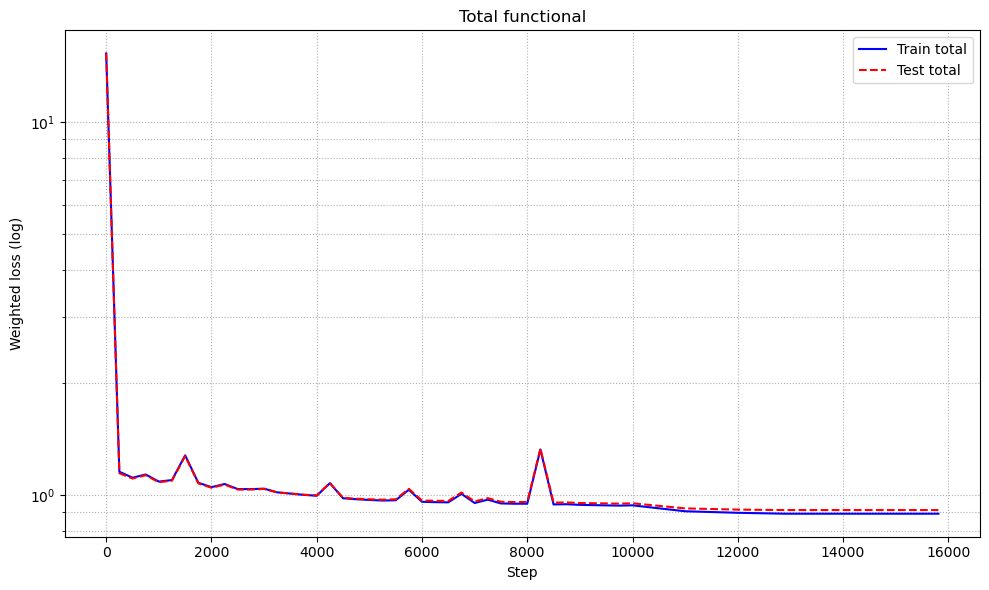

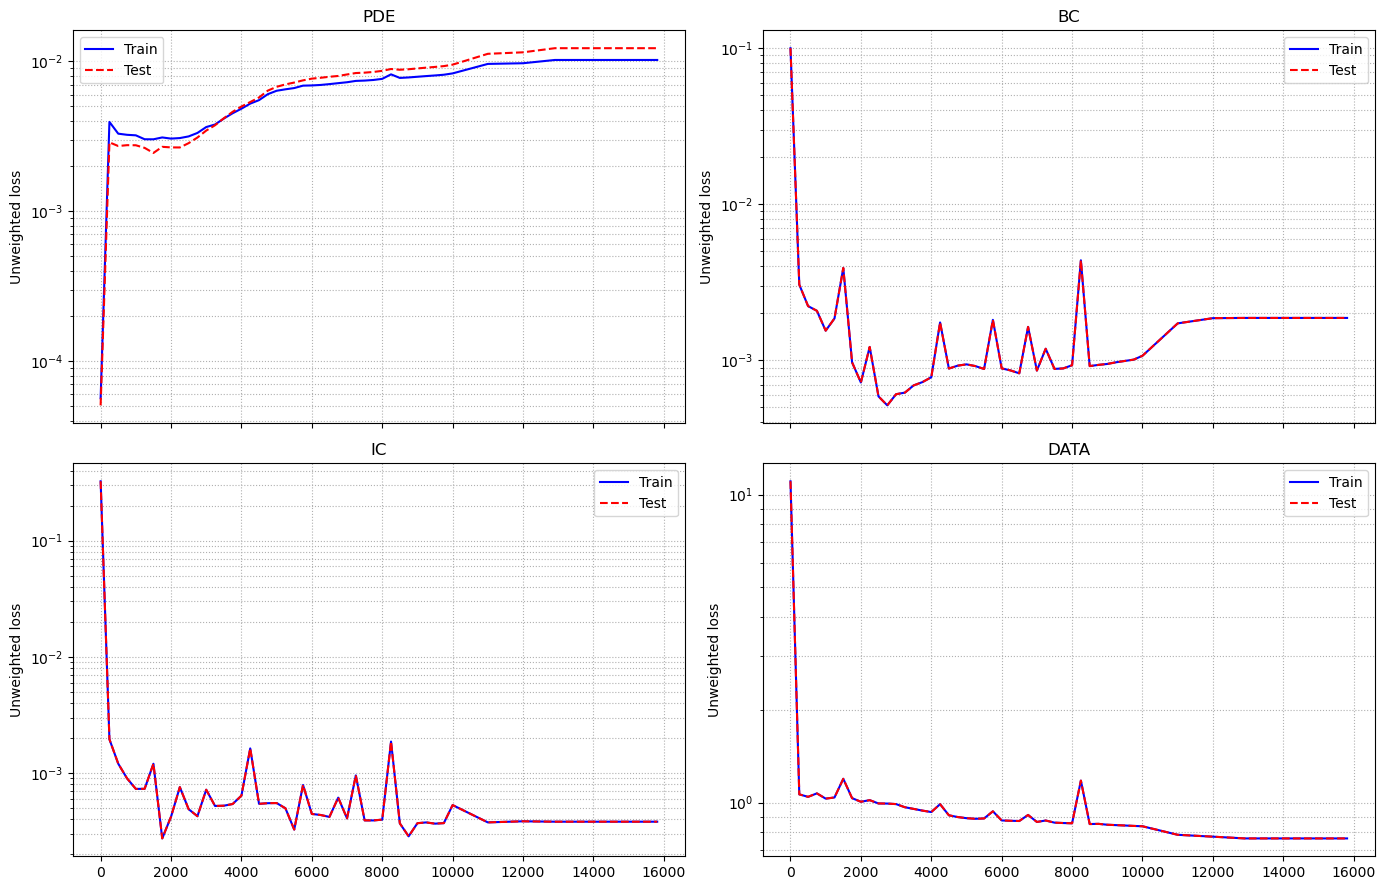

In [ ]:
losshistory, train_state = model.train(
    iterations=10000, display_every=250, callbacks=[var_callback]
)

lab_idx = {'PDE':0, 'BC':1, 'IC':2, 'DATA':3}
steps        = np.array(losshistory.steps)                
train_loss   = np.array(losshistory.loss_train)          
test_loss    = np.array(losshistory.loss_test)           
labels       = ['PDE', 'BC', 'IC', 'DATA']
weights      = np.array([10.0, 10.0, 10.0, 1.0])        

fig, ax = plt.subplots(figsize=(10, 6))
ax.semilogy(steps, train_loss.sum(axis=1), 'b-',  label='Train total')
ax.semilogy(steps, test_loss.sum(axis=1),  'r--', label='Test total')
ax.set_xlabel('Step'); ax.set_ylabel('Weighted loss (log)')
ax.set_title('Total functional'); ax.legend(); ax.grid(True, which='both', ls=':')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
for ax, lab, w in zip(axes.flat, labels, weights):
    ax.semilogy(steps, train_loss[:, lab_idx[lab]] / w, 'b-',  label='Train')
    ax.semilogy(steps, test_loss[:,  lab_idx[lab]] / w, 'r--', label='Test')
    ax.set_ylabel('Unweighted loss'); ax.set_title(lab)
    ax.legend(); ax.grid(True, which='both', ls=':')
plt.tight_layout()
plt.show()